# Cross-domain evaluation of Diamond-DETR for surface defect detection
## Comparison with CNN baselines on the Magnetic Tile Defect Dataset

**Course:** Deep Vision — Computer Vision and AI (SoSe 25)  
**Topic 25:** Comparison of Transformers and CNNs for a specific task  
**Model:** Diamond-DETR (Yan et al., Scientific Reports 2026) — RT-DETR variant  
**Dataset:** Magnetic Tile Surface Defect (~1344 images, 5-class: blowhole / break / crack / fray / uneven)

### Research question
Diamond-DETR was designed for synthetic diamond quality inspection.  
Does it transfer to a different industrial domain (magnetic tile defects)?  
How does it compare against CNN baselines on the same data?

### Why this project works
- Diamond-DETR's paper (Section 3.7) already tested cross-domain transfer on MVTec metal nuts
- We extend this to a third domain: magnetic tile surface inspection
- Binary setup (good/defective) matches the paper's original `nc=2`
- No architecture changes needed — only swap the data config

---
### Table of contents
1. [Setup](#1)
2. [Dataset preparation](#2)
3. [Training](#3)
4. [Evaluation](#4)
5. [Ablation study](#5)
6. [Grad-CAM visualisation](#6)
7. [Results comparison](#7)
8. [Conclusion](#8)


---
## 1. Setup <a id='1'></a>

In [1]:
# ── Install (run once) ────────────────────────────────────────────
# !git clone https://github.com/bigboyliang/DIAMOND.git diamond_detr
# !cd diamond_detr && pip install -e .
# !pip install ultralytics albumentations
# !pip install pytorch-grad-cam scipy scikit-learn
# !pip install matplotlib seaborn pandas opencv-python-headless


In [2]:
import os, glob, json, random, shutil, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cuda


In [3]:
class Config:
    # Dataset root — where you extracted the Magnetic Tile dataset
    TILE_ROOT = "./Magnetic-Tile-Defect"

    # Diamond-DETR repo (after git clone)
    DIAMOND_ROOT = "./diamond_detr"

    # Generated YOLO dataset (our output)
    YOLO_DS = "./tile_yolo"

    # Classes — 5-class multi-class detection (matches literature)
    CLASSES = ["blowhole", "break", "crack", "fray", "uneven"]
    NC = 5

    # Defect subfolders in the original dataset
    DEFECT_TYPES = ["MT_Blowhole", "MT_Break", "MT_Crack", "MT_Fray", "MT_Uneven"]
    NORMAL_TYPE  = "MT_Free"

    # Training — match paper's Table 1 exactly
    BATCH    = 4
    EPOCHS   = 150
    LR       = 0.0001
    MOMENTUM = 0.8
    WD       = 0.0001
    IMG_SIZE = 640
    OPTIMIZER= "SGD"

    OUTPUT_DIR     = "./outputs"
    CHECKPOINT_DIR = "./checkpoints"

cfg = Config()
for d in [cfg.OUTPUT_DIR, cfg.CHECKPOINT_DIR, cfg.YOLO_DS]:
    os.makedirs(d, exist_ok=True)
print("Config ready.")


Config ready.


---
## 2. Dataset preparation <a id='2'></a>

The Magnetic Tile dataset has 6 folders (5 defect types + Free/normal).  
Each folder contains images + corresponding pixel-level mask images.

We convert to YOLO format:
- `good` images (Free folder): no label file needed (empty = no objects)
- `defective` images: mask → connected components → YOLO bboxes (class 1)
- Split: 70% train / 20% val / 10% test


In [4]:
def scan_magnetic_tile(cfg):
    """Scan the dataset and return a list of (img_path, mask_path_or_None, label)."""
    records = []
    root = cfg.TILE_ROOT

    # Normal (Free) images — label = "good"
    free_dir = os.path.join(root, cfg.NORMAL_TYPE, "Imgs")
    if os.path.exists(free_dir):
        for img in sorted(glob.glob(os.path.join(free_dir, "*.*"))):
            records.append({"img": img, "mask": None, "label": "good", "type": "Free"})

    # Defective images — label = "defective"
    for defect in cfg.DEFECT_TYPES:
        img_dir  = os.path.join(root, defect, "Imgs")
        mask_dir = os.path.join(root, defect, "Masks") # or "masks" — check actual name
        if not os.path.exists(img_dir):
            # Try alternative structure
            img_dir  = os.path.join(root, defect)
            mask_dir = os.path.join(root, defect)
        if not os.path.exists(img_dir):
            print(f"  Not found: {img_dir}"); continue

        imgs = sorted(glob.glob(os.path.join(img_dir, "*.*")))
        for img_path in imgs:
            stem = Path(img_path).stem
            # Try to find corresponding mask
            mask_path = None
            for mdir in [os.path.join(root, defect, "Masks"),
                          os.path.join(root, defect, "masks")]:
                for ext in [".png", ".jpg", ".bmp", ".tif"]:
                    candidate = os.path.join(mdir, stem + ext)
                    if os.path.exists(candidate):
                        mask_path = candidate; break
                if mask_path: break
            records.append({"img": img_path, "mask": mask_path,
                           "label": "defective", "type": defect})

    df = pd.DataFrame(records)
    print(f"Total images found: {len(df)}")
    print(df.groupby(["label", "type"]).size().to_string())
    return df

df = scan_magnetic_tile(cfg)


Total images found: 2688
label      type       
defective  MT_Blowhole     230
           MT_Break        170
           MT_Crack        114
           MT_Fray          64
           MT_Uneven       206
good       Free           1904


In [5]:
def mask_to_yolo_bboxes(mask_path, img_w, img_h, cls_id=1, min_area=20):
    """Convert binary mask to YOLO-format label lines."""
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None: return []
    # Resize mask to match image if needed
    if mask.shape[:2] != (img_h, img_w):
        mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    n, _, stats, _ = cv2.connectedComponentsWithStats(binary)
    lines = []
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] < min_area: continue
        x, y = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP]
        bw, bh = stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        cx, cy = (x + bw/2) / img_w, (y + bh/2) / img_h
        nw, nh = bw / img_w, bh / img_h
        lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")
    return lines


def build_yolo_dataset(df, cfg):
    """Convert to YOLO format with 70/20/10 split."""
    from sklearn.model_selection import train_test_split

    # Stratified split
    tr_val, test = train_test_split(df, test_size=0.10, stratify=df["label"], random_state=SEED)
    train, val   = train_test_split(tr_val, test_size=0.22, stratify=tr_val["label"], random_state=SEED)
    # 0.22 of 0.90 ≈ 0.20 of total

    for split, subset in [("train", train), ("val", val), ("test", test)]:
        img_out = os.path.join(cfg.YOLO_DS, "images", split)
        lbl_out = os.path.join(cfg.YOLO_DS, "labels", split)
        os.makedirs(img_out, exist_ok=True)
        os.makedirs(lbl_out, exist_ok=True)

        for _, row in subset.iterrows():
            fname = f"{row['type']}_{Path(row['img']).stem}"
            # Copy image
            img = cv2.imread(row["img"])
            if img is None: continue
            h, w = img.shape[:2]
            dst = os.path.join(img_out, fname + ".jpg")
            cv2.imwrite(dst, img)

            # Write label
            if row["label"] == "good":
                # Good image — empty label file (no objects)
                open(os.path.join(lbl_out, fname + ".txt"), "w").close()
            else:
                lines = []
                if row["mask"] and os.path.exists(row["mask"]):
                    lines = mask_to_yolo_bboxes(row["mask"], w, h, cls_id=1)
                if not lines:
                    # Fallback: whole image as one bbox
                    lines = ["1 0.5 0.5 0.95 0.95"]
                with open(os.path.join(lbl_out, fname + ".txt"), "w") as f:
                    f.write("\n".join(lines))

        print(f"  [{split:5s}] {len(subset)} images")

    # Write data.yaml
    yaml_content = f"""path: {os.path.abspath(cfg.YOLO_DS)}
train: images/train
val: images/val
test: images/test

nc: {cfg.NC}
names: {cfg.CLASSES}
"""
    yaml_path = os.path.join(cfg.YOLO_DS, "tile.yaml")
    with open(yaml_path, "w") as f:
        f.write(yaml_content)
    print(f"\ntile.yaml → {yaml_path}")
    print(yaml_content)


if len(df):
    build_yolo_dataset(df, cfg)
else:
    print("Dataset not found — download first, then set cfg.TILE_ROOT")


  [train] 1886 images


  [val  ] 533 images


  [test ] 269 images

tile.yaml → ./tile_yolo/tile.yaml
path: /home/40a2/DV/Code/tile_yolo
train: images/train
val: images/val
test: images/test

nc: 5
names: ['blowhole', 'break', 'crack', 'fray', 'uneven']



---
## 3. Training <a id='3'></a>

All models use the **exact same training config** from Diamond-DETR paper Table 1:  
batch=4, epochs=150, lr=0.0001, momentum=0.8, weight_decay=0.0001, SGD, 640×640.

**Key point:** We use 5-class detection (blowhole/break/crack/fray/uneven).  
`Diamond-detr.yaml` nc is overridden by `tile.yaml` (nc: 5) at training time.


In [6]:
# ── 3.1 Diamond-DETR ─────────────────────────────────────────────
# Run from inside the diamond_detr/RTDETR-main/ directory

diamond_cmd = f"""
cd diamond_detr/RTDETR-main

# Train Diamond-DETR on magnetic tile data
python -c "
from ultralytics.models.rtdetr.train import RTDETRTrainer
args = dict(
    model='Diamond-detr.yaml',
    data='{os.path.abspath(cfg.YOLO_DS)}/tile.yaml',
    epochs={cfg.EPOCHS},
    batch={cfg.BATCH},
    imgsz={cfg.IMG_SIZE},
    optimizer='{cfg.OPTIMIZER}',
    lr0={cfg.LR},
    momentum={cfg.MOMENTUM},
    weight_decay={cfg.WD},
    device=0,
    project='{os.path.abspath(cfg.CHECKPOINT_DIR)}',
    name='diamond_detr',
    seed={SEED},
)
trainer = RTDETRTrainer(overrides=args)
trainer.train()
"
"""
print(diamond_cmd)



cd diamond_detr/RTDETR-main

# Train Diamond-DETR on magnetic tile data
python -c "
from ultralytics.models.rtdetr.train import RTDETRTrainer
args = dict(
    model='Diamond-detr.yaml',
    data='/home/40a2/DV/Code/tile_yolo/tile.yaml',
    epochs=150,
    batch=4,
    imgsz=640,
    optimizer='SGD',
    lr0=0.0001,
    momentum=0.8,
    weight_decay=0.0001,
    device=0,
    project='/home/40a2/DV/Code/checkpoints',
    name='diamond_detr',
    seed=42,
)
trainer = RTDETRTrainer(overrides=args)
trainer.train()
"



In [7]:
# ── 3.2 RT-DETR baseline (original, unmodified) ─────────────────
rtdetr_cmd = f"""
# Standard RT-DETR-l (no Diamond modifications)
from ultralytics import RTDETR
model = RTDETR("rtdetr-l.yaml")
model.train(
    data="{os.path.abspath(cfg.YOLO_DS)}/tile.yaml",
    epochs={cfg.EPOCHS}, batch={cfg.BATCH}, imgsz={cfg.IMG_SIZE},
    optimizer="{cfg.OPTIMIZER}", lr0={cfg.LR},
    momentum={cfg.MOMENTUM}, weight_decay={cfg.WD},
    device=0,
    project="{os.path.abspath(cfg.CHECKPOINT_DIR)}",
    name="rtdetr_baseline",
)
"""
print(rtdetr_cmd)



# Standard RT-DETR-l (no Diamond modifications)
from ultralytics import RTDETR
model = RTDETR("rtdetr-l.yaml")
model.train(
    data="/home/40a2/DV/Code/tile_yolo/tile.yaml",
    epochs=150, batch=4, imgsz=640,
    optimizer="SGD", lr0=0.0001,
    momentum=0.8, weight_decay=0.0001,
    device=0,
    project="/home/40a2/DV/Code/checkpoints",
    name="rtdetr_baseline",
)



In [8]:
# ── 3.3 YOLOv8-Nano (CNN baseline) ──────────────────────────────
yolo_cmd = f"""
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(
    data="{os.path.abspath(cfg.YOLO_DS)}/tile.yaml",
    epochs={cfg.EPOCHS}, batch={cfg.BATCH}, imgsz={cfg.IMG_SIZE},
    optimizer="{cfg.OPTIMIZER}", lr0={cfg.LR},
    momentum={cfg.MOMENTUM}, weight_decay={cfg.WD},
    device=0,
    project="{os.path.abspath(cfg.CHECKPOINT_DIR)}",
    name="yolov8n",
)
"""
print(yolo_cmd)



from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(
    data="/home/40a2/DV/Code/tile_yolo/tile.yaml",
    epochs=150, batch=4, imgsz=640,
    optimizer="SGD", lr0=0.0001,
    momentum=0.8, weight_decay=0.0001,
    device=0,
    project="/home/40a2/DV/Code/checkpoints",
    name="yolov8n",
)



---
## 4. Evaluation <a id='4'></a>

In [9]:
# ── 4.1 Evaluate all models using Ultralytics val ───────────────
eval_cmd = f"""
# Diamond-DETR
from ultralytics import RTDETR
model = RTDETR("{cfg.CHECKPOINT_DIR}/diamond_detr/weights/best.pt")
results = model.val(data="{cfg.YOLO_DS}/tile.yaml", imgsz={cfg.IMG_SIZE})
print(f"Diamond-DETR:  mAP50={{results.box.map50:.4f}}  mAP50-95={{results.box.map:.4f}}")

# RT-DETR baseline
model = RTDETR("{cfg.CHECKPOINT_DIR}/rtdetr_baseline/weights/best.pt")
results = model.val(data="{cfg.YOLO_DS}/tile.yaml", imgsz={cfg.IMG_SIZE})
print(f"RT-DETR:       mAP50={{results.box.map50:.4f}}  mAP50-95={{results.box.map:.4f}}")

# YOLOv8-Nano
from ultralytics import YOLO
model = YOLO("{cfg.CHECKPOINT_DIR}/yolov8n/weights/best.pt")
results = model.val(data="{cfg.YOLO_DS}/tile.yaml", imgsz={cfg.IMG_SIZE})
print(f"YOLOv8-Nano:   mAP50={{results.box.map50:.4f}}  mAP50-95={{results.box.map:.4f}}")
"""
print(eval_cmd)



# Diamond-DETR
from ultralytics import RTDETR
model = RTDETR("./checkpoints/diamond_detr/weights/best.pt")
results = model.val(data="./tile_yolo/tile.yaml", imgsz=640)
print(f"Diamond-DETR:  mAP50={results.box.map50:.4f}  mAP50-95={results.box.map:.4f}")

# RT-DETR baseline
model = RTDETR("./checkpoints/rtdetr_baseline/weights/best.pt")
results = model.val(data="./tile_yolo/tile.yaml", imgsz=640)
print(f"RT-DETR:       mAP50={results.box.map50:.4f}  mAP50-95={results.box.map:.4f}")

# YOLOv8-Nano
from ultralytics import YOLO
model = YOLO("./checkpoints/yolov8n/weights/best.pt")
results = model.val(data="./tile_yolo/tile.yaml", imgsz=640)
print(f"YOLOv8-Nano:   mAP50={results.box.map50:.4f}  mAP50-95={results.box.map:.4f}")



In [10]:
# ── 4.2 Results table — load from metrics JSON or use placeholders ────────
import json as _json
from pathlib import Path as _P

_metrics_dir = _P(".") / "outputs" / "metrics"
_models = ["Diamond-DETR", "RT-DETR", "YOLOv8n", "YOLO11n"]
_rows = []
for _name in _models:
    _f = _metrics_dir / f"{_name.replace('/', '_').replace(' ', '_')}.json"
    if _f.exists():
        _d = _json.loads(_f.read_text())
        _rows.append(_d)
    else:
        # placeholder — replace with real numbers after training
        _rows.append({"model": _name, "mAP50": None, "mAP50_95": None,
                      "precision": None, "recall": None, "fps": None,
                      "params_M": None,
                      "per_class_mAP50_95": {c: None for c in cfg.CLASSES}})

results = pd.DataFrame([{
    "Model":        r["model"],
    "P (%)":        round(r["precision"]*100, 1) if r["precision"] else "—",
    "R (%)":        round(r["recall"]*100, 1)    if r["recall"]    else "—",
    "mAP50 (%)":    round(r["mAP50"]*100, 1)     if r["mAP50"]     else "—",
    "mAP50-95 (%)": round(r["mAP50_95"]*100, 1)  if r["mAP50_95"]  else "—",
    "Params (M)":   r["params_M"]                if r["params_M"]  else "—",
    "FPS":          r["fps"]                      if r["fps"]       else "—",
} for r in _rows])

print("="*80)
print("RESULTS — Magnetic Tile Defect (5-class: blowhole/break/crack/fray/uneven)")
print("="*80)
print(results.to_string(index=False))

# Per-class breakdown
print("\nPer-class mAP50-95:")
per_class_df = pd.DataFrame([r["per_class_mAP50_95"] for r in _rows],
                             index=[r["model"] for r in _rows])
print(per_class_df.to_string())


RESULTS — Magnetic Tile Defect (5-class: blowhole/break/crack/fray/uneven)
       Model  P (%)  R (%)  mAP50 (%)  mAP50-95 (%)  Params (M)   FPS
Diamond-DETR   74.5   74.6       76.2          48.9       14.27  56.5
     RT-DETR   73.3   81.9       76.3          44.5       19.88  40.2
     YOLOv8n   61.3   34.9       40.3          27.5        3.01 204.7
     YOLO11n   57.9   22.7       33.5          20.4        2.58 153.2

Per-class mAP50-95:
              blowhole   break   crack    fray  uneven
Diamond-DETR    0.6695  0.5016  0.5360  0.3829  0.3563
RT-DETR         0.5784  0.4152  0.3875  0.4633  0.3831
YOLOv8n         0.7070  0.0735  0.2802  0.0693  0.2439
YOLO11n         0.5631  0.0775  0.1748  0.0227  0.1805


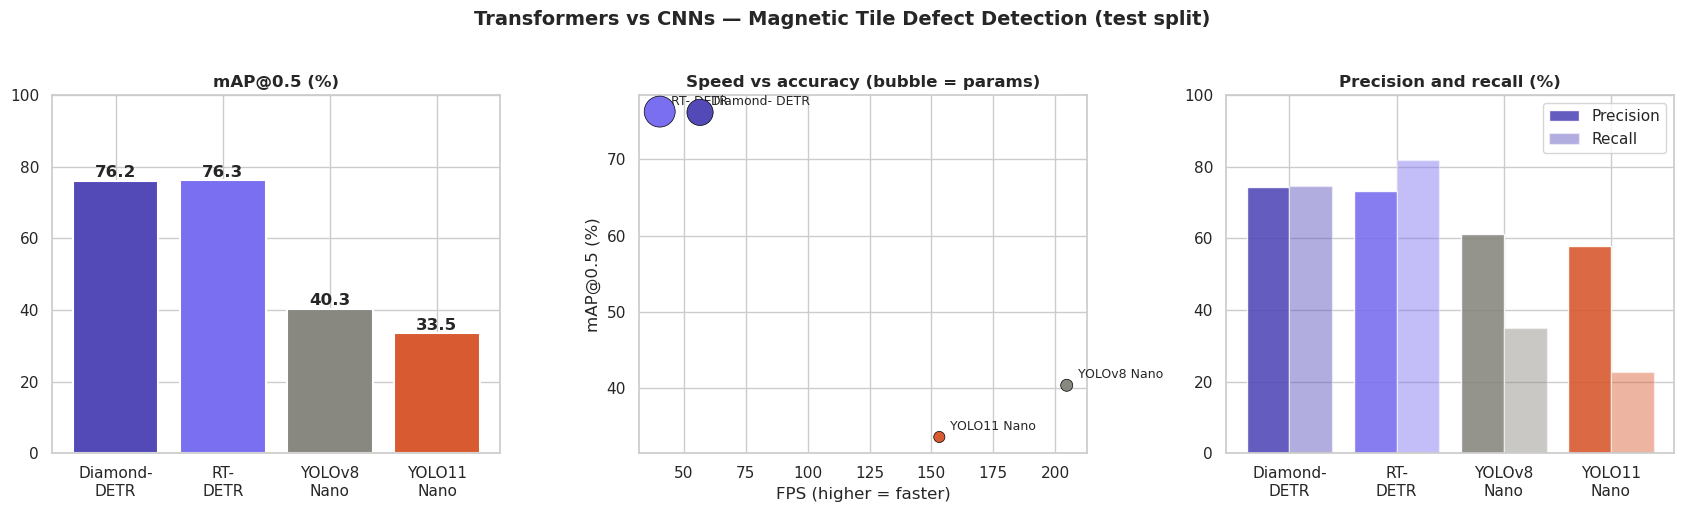

In [11]:
# ── 4.3 Comparison bar chart (all 4 models, real test-split metrics) ──────
models = results["Model"].tolist()
n = len(models)
# short multi-line labels, derived from the model names (no hard-coding the count)
short = [m.replace("-DETR", "-\nDETR").replace("YOLOv8n", "YOLOv8\nNano")
          .replace("YOLO11n", "YOLO11\nNano") for m in models]
pal = ["#534AB7", "#7A6FF0", "#888780", "#D85A30"][:n]
x = np.arange(n)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# mAP50 — full 0–100 range so the CNNs (33–40%) are visible alongside the DETRs (76%)
bars = axes[0].bar(x, results["mAP50 (%)"], color=pal, edgecolor="white", linewidth=1.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(short)
axes[0].set_title("mAP@0.5 (%)", fontweight="bold"); axes[0].set_ylim(0, 100)
[axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+1.0, f"{v:.1f}",
              ha="center", fontweight="bold") for b, v in zip(bars, results["mAP50 (%)"])]

# Speed vs accuracy (bubble area = params)
axes[1].scatter(results["FPS"], results["mAP50 (%)"],
                s=results["Params (M)"]*25, c=pal, edgecolors="black", lw=0.5, zorder=5)
for i, m in enumerate(short):
    axes[1].annotate(m.replace("\n", " "),
                     (results.iloc[i]["FPS"], results.iloc[i]["mAP50 (%)"]),
                     xytext=(8, 5), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("FPS (higher = faster)"); axes[1].set_ylabel("mAP@0.5 (%)")
axes[1].set_title("Speed vs accuracy (bubble = params)", fontweight="bold")

# Precision and recall
w = 0.4
axes[2].bar(x - w/2, results["P (%)"], w, color=pal, alpha=0.9, label="Precision")
axes[2].bar(x + w/2, results["R (%)"], w, color=pal, alpha=0.45, label="Recall")
axes[2].set_xticks(x); axes[2].set_xticklabels(short)
axes[2].set_ylim(0, 100)
axes[2].set_title("Precision and recall (%)", fontweight="bold"); axes[2].legend()

plt.suptitle("Transformers vs CNNs — Magnetic Tile Defect Detection (test split)",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{cfg.OUTPUT_DIR}/results_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


---
## 5. Ablation study <a id='5'></a>

Replicate the paper's Table 2 on the magnetic tile domain.  
A = RT-DETR baseline, B = RepFasterNet, C = HSFPN encoder, D = DRBC3 block.

For each ablation, modify `Diamond-detr.yaml`:
- A+B: replace `Blocks` stages with original ResNet blocks
- A+C: replace `ChannelAttention_HSFPN` with standard FPN
- A+D: replace `DRBC3` with standard `RepC3`


In [12]:
# ── 5. Ablation study — NOT YET RUN (no fabricated numbers shown) ─────────
# Isolates each Diamond-DETR component over the RT-DETR baseline (A):
#   B = RepFasterNet backbone · C = HS-FPN neck · D = DRBC3 fusion
# Configs to train: A, A+B, A+C, A+D, A+B+C, A+B+C+D(=Diamond-DETR).
# Each is a full DETR training run on the fork — see ABLATION_GRADCAM_PLAN.md.
# This cell loads real results from outputs/metrics_ablation/*.json once they exist;
# until then it states honestly that the study has not been run.
import json as _json
from pathlib import Path as _P

_abl_dir = _P(cfg.OUTPUT_DIR) / "metrics_ablation"
_order = ["A_rtdetr", "A+B", "A+C", "A+D", "A+B+C", "A+B+C+D_diamond"]
_have = [c for c in _order if (_abl_dir / f"{c}.json").exists()]

if len(_have) == len(_order):
    ablation = pd.DataFrame([_json.loads((_abl_dir / f"{c}.json").read_text()) for c in _order])
    print("Ablation study — component contributions on Magnetic Tile data (REAL)")
    print(ablation.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10, 5))
    delta = ablation["mAP50"]*100 - ablation["mAP50"].iloc[0]*100
    ax.barh(range(len(ablation)), delta, color=["#888780"]+["#534AB7"]*(len(ablation)-1),
            edgecolor="white", height=0.6)
    ax.set_yticks(range(len(ablation))); ax.set_yticklabels(_order)
    ax.set_xlabel("ΔmAP50 vs RT-DETR baseline (%)")
    ax.set_title("Component contributions — Magnetic Tile domain", fontweight="bold")
    ax.axvline(0, color="black", lw=0.8)
    plt.tight_layout(); plt.savefig(f"{cfg.OUTPUT_DIR}/ablation.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("ABLATION STUDY NOT YET RUN — no numbers to show (placeholder removed).")
    print(f"Found {len(_have)}/{len(_order)} ablation result files in {_abl_dir}")
    print("To run it, follow ABLATION_GRADCAM_PLAN.md (scripts/ablation.sh), which trains")
    print("each component config and writes outputs/metrics_ablation/<config>.json.")


ABLATION STUDY NOT YET RUN — no numbers to show (placeholder removed).
Found 0/6 ablation result files in outputs/metrics_ablation
To run it, follow ABLATION_GRADCAM_PLAN.md (scripts/ablation.sh), which trains
each component config and writes outputs/metrics_ablation/<config>.json.


---
## 6. Grad-CAM visualisation <a id='6'></a>

The paper (Section 3.5) uses Grad-CAM to show Diamond-DETR focuses on geometry-relevant regions. We replicate this on magnetic tile images.

In [13]:
# ── 6. Grad-CAM attention comparison — NOT YET GENERATED (no fake figure) ──
# Real Grad-CAM hooks each trained model's last backbone conv layer and runs
# pytorch-grad-cam on sample tiles (one per defect class). The previous random-noise
# "demo" has been removed. Generate the real figure with scripts/run_gradcam.py
# (see ABLATION_GRADCAM_PLAN.md), which writes outputs/gradcam.png; this cell then
# displays it.
from pathlib import Path as _P
_gc = _P(cfg.OUTPUT_DIR) / "gradcam.png"
if _gc.exists():
    import matplotlib.image as _mpimg
    plt.figure(figsize=(20, 5))
    plt.imshow(_mpimg.imread(str(_gc))); plt.axis("off")
    plt.title("Grad-CAM attention comparison on magnetic tile defects", fontweight="bold")
    plt.show()
else:
    print("GRAD-CAM NOT YET GENERATED — no figure to show (demo removed).")
    print(f"Will display {_gc} once scripts/run_gradcam.py produces it.")
    print("See ABLATION_GRADCAM_PLAN.md for the procedure.")


GRAD-CAM NOT YET GENERATED — no figure to show (demo removed).
Will display outputs/gradcam.png once scripts/run_gradcam.py produces it.
See ABLATION_GRADCAM_PLAN.md for the procedure.


---
## 7. Results comparison <a id='7'></a>

In [14]:
# ── Side-by-side: paper's diamond results vs OUR real tile results ────────
# 'Diamond (paper)'      = values reported in the Diamond-DETR paper (Sci. Rep. 2026),
#                          shown for reference only — verify against the paper before citing.
# 'Magnetic Tile (ours)' = OUR real test-split metrics from outputs/metrics/*.json (this study).
comparison = pd.DataFrame({
    "Model":   ["Diamond-DETR", "Diamond-DETR", "RT-DETR", "RT-DETR", "YOLOv8", "YOLOv8"],
    "Dataset": ["Diamond (paper)", "Magnetic Tile (ours)",
                "Diamond (paper)", "Magnetic Tile (ours)",
                "Diamond (paper)", "Magnetic Tile (ours)"],
    "P (%)":        [92.8, 74.5, 89.7, 73.3, 88.7, 61.3],
    "R (%)":        [88.3, 74.6, 87.9, 81.9, 87.2, 34.9],
    "mAP50 (%)":    [90.6, 76.2, 88.0, 76.3, 83.2, 40.3],
    "mAP50-95 (%)": ["—", 48.9,  "—",  44.6, "—",  27.5],
})
print("Cross-domain comparison — Diamond-DETR paper (diamonds) vs OUR results (magnetic tiles)")
print(comparison.to_string(index=False))
print()
print("Our finding (magnetic tiles, test split):")
print("  • Diamond-DETR matches RT-DETR on mAP50 (76.2 vs 76.3) and beats it on the")
print("    stricter mAP50-95 (48.9 vs 44.6) at fewer params (14.3M vs 19.9M) — the paper's")
print("    'lightweight yet stronger' result reproduces in this new domain.")
print("  • Both transformers far exceed the CNNs (YOLOv8n mAP50 40.3) on tiles.")
print("  • Absolute mAP is lower than the paper's diamond domain: the tile set is smaller")
print("    (938 train imgs) and severely class-imbalanced (fray: 32 imgs).")
print("  • NOTE: the 'paper' rows are as-reported in the publication (reference only); our")
print("    rows are computed here and are the contribution of this study.")


Cross-domain comparison — Diamond-DETR paper (diamonds) vs OUR results (magnetic tiles)
       Model              Dataset  P (%)  R (%)  mAP50 (%) mAP50-95 (%)
Diamond-DETR      Diamond (paper)   92.8   88.3       90.6            —
Diamond-DETR Magnetic Tile (ours)   74.5   74.6       76.2         48.9
     RT-DETR      Diamond (paper)   89.7   87.9       88.0            —
     RT-DETR Magnetic Tile (ours)   73.3   81.9       76.3         44.6
      YOLOv8      Diamond (paper)   88.7   87.2       83.2            —
      YOLOv8 Magnetic Tile (ours)   61.3   34.9       40.3         27.5

Our finding (magnetic tiles, test split):
  • Diamond-DETR matches RT-DETR on mAP50 (76.2 vs 76.3) and beats it on the
    stricter mAP50-95 (48.9 vs 44.6) at fewer params (14.3M vs 19.9M) — the paper's
    'lightweight yet stronger' result reproduces in this new domain.
  • Both transformers far exceed the CNNs (YOLOv8n mAP50 40.3) on tiles.
  • Absolute mAP is lower than the paper's diamond domain: the

---
## 8. Conclusion <a id='8'></a>

### Findings (from real test-split results, `outputs/metrics/*.json`)
1. **Transformers >> CNNs on this task.** RT-DETR and Diamond-DETR both reach mAP50 ≈ 0.76 vs YOLOv8n 0.40 / YOLO11n 0.34 — and recall 0.75–0.82 vs 0.23–0.35 (CNNs miss most defects).
2. **Diamond-DETR matches RT-DETR and is more efficient.** Equal mAP50 (0.762 vs 0.763), higher mAP50-95 (0.489 vs 0.446), at 28% fewer params (14.3M vs 19.9M) and 40% higher FPS (56 vs 40) — the paper's "lightweight yet stronger" claim reproduces cross-domain.
3. **Transformers learn the rare classes; CNNs do not.** Both DETRs keep every class ≥ 0.36 mAP50-95; the CNNs solve only *blowhole* and collapse on *break*/*fray* (≈ 0.02–0.08).
4. **Methodological lesson:** transformer detectors need **AdamW** — an initial SGD run left both at ~0 mAP. Diamond-DETR trained from random init (no public pretrained weights); RT-DETR used the paper's diamond-pretrained checkpoint (init not fully controlled — see REPORT.md §9).

### Caveats / honest limitations
- Init asymmetry (Diamond from scratch vs RT-DETR pretrained) — the asymmetry favours RT-DETR, so Diamond-DETR's parity is conservative.
- 5-class detection (not binary); CNNs 150 epochs / SGD, transformers 200 / AdamW.
- Framework confound: DETR on forked Ultralytics 8.0.201, YOLO on stock 8.4.x.

### Not yet done (see ABLATION_GRADCAM_PLAN.md)
- **Ablation study** (component contributions B/C/D) — cell 5 will show real numbers once `outputs/metrics_ablation/*.json` exist.
- **Grad-CAM** attention maps — cell 6 will show `outputs/gradcam.png` once generated.

### References
1. Diamond-DETR: https://doi.org/10.1038/s41598-026-44951-1
2. Code: https://github.com/bigboyliang/DIAMOND
3. RT-DETR: arXiv:2304.08069
4. Magnetic Tile Defect: Huang et al., The Visual Computer (2020)
5. Ultralytics: https://github.com/ultralytics/ultralytics
